In [462]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [463]:
import pandas as pd
import numpy as np

from matplotlib import pyplot as plt
import matplotlib
import seaborn as sns
import copy
import pickle
import warnings
warnings.filterwarnings('ignore')
import shap
from models import *
from utilities import *

In [464]:
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42 
matplotlib.rc('font', family='sans-serif') 
matplotlib.rc('font', serif='Helvetica Neue') 

In [465]:
##########################################################################################################

In [466]:
import tensorflow as tf
# tf.compat.v1.disable_v2_behavior()

In [467]:
# shap.explainers._deep.deep_tf.op_handlers["AddV2"] = shap.explainers._deep.deep_tf.passthrough 
# shap.explainers._deep.deep_tf.op_handlers["FusedBatchNormV3"] = shap.explainers._deep.deep_tf.passthrough

In [468]:
################### data import ###############

In [469]:
data_dir = '../results/data/'
data_copy = pd.read_pickle(data_dir + 'LSTM_processed_data_dy_filter.pkl')
ba_copy = pd.read_pickle(data_dir + 'LSTM_processed_data_ba_filter.pkl')

In [470]:
data_copy['Id_encoded'], uniques = pd.factorize(data_copy['SCCRIP_ID'])
mapping_dict = {value: index for index, value in enumerate(uniques)}

In [471]:
ba_copy['Id_encoded'] = ba_copy['SCCRIP_ID'].map(mapping_dict)
ba_copy = ba_copy[ba_copy['Id_encoded'].notna()]
ba_copy = ba_copy.drop_duplicates(subset='SCCRIP_ID', keep='last')
ba_copy.drop('SCCRIP_ID', inplace=True, axis=1)

In [472]:
ba_copy = ba_copy.fillna(0)
data_copy = data_copy.fillna(0)

bmt = read_sas('../data/Apply_MI_Zheng_2023_01/othertreatment_summary.sas7bdat')
bmt = bmt[['SCCRIP_ID', 'BMT']]
bmt_ids = set(bmt[bmt['BMT'] == 1].SCCRIP_ID)
data_copy_filter = data_copy[~data_copy["SCCRIP_ID"].isin(bmt_ids)]
len(data_copy_filter.SCCRIP_ID.unique())

1264

In [473]:
len(data_copy_filter.SCCRIP_ID.unique())

1264

In [474]:
feature_dy = data_copy_filter.drop(['HU_status','Id_encoded','SCCRIP_ID'],axis=1).columns
feature_ba = ba_copy.drop(['Id_encoded'], axis=1).columns

In [475]:
################ data process ##################

In [476]:
seq_length = 5

In [477]:
sequences, seq_ba, labels, date,  y_target = create_dataset(data_copy_filter, ba_copy, seq_length, mapping_dict)
sequences_copy, seq_ba_copy, labels_copy, date_copy, y_target_copy = shuffle_dataset(sequences, seq_ba, labels, date, y_target)
X, y, X_bg, dt, ls, seq_map = create_sequences_with_background(sequences_copy, labels_copy, seq_ba_copy, date_copy,y_target_copy, seq_length)
X_normalized, X_bg_normalized = normalize_X(X, X_bg)

In [478]:
(X_train,X_val,X_test,
            X_bg_train,X_bg_val,X_bg_test,
            dt_train, dt_val, dt_test, 
            y_train,y_val,y_test,
            ls_train, ls_val, ls_test,
            seq_map_train, seq_map_val, seq_map_test) = split_dataset(X_normalized, X_bg_normalized,dt, y, ls, seq_map)


In [479]:
X_train.shape, X_bg_train.shape, dt_train.shape

((18101, 5, 786), (18101, 1, 23), (18101, 1, 1))

In [480]:
# Initialize the model class
combined_model = CombinedLSTMModel(seq_length=seq_length, n_features=int(X_train.shape[2]), bg_features=int(X_bg_train.shape[2]))

Model input shapes: (None, 5, 786) (None, 1, 23) (None, 1, 1)
Model: "CombinedLSTMModel"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_bg (InputLayer)       [(None, 1, 23)]              0         []                            
                                                                                                  
 input_dt (InputLayer)       [(None, 1, 1)]               0         []                            
                                                                                                  
 input_seq (InputLayer)      [(None, 5, 786)]             0         []                            
                                                                                                  
 bg_plus_dt (Concatenate)    (None, 1, 24)                0         ['input_bg[0][0]',            
                    

In [481]:
# Train the model
history = combined_model.train(
    X_train, X_bg_train, dt_train, y_train,
    X_val,   X_bg_val,   dt_val,   y_val,
    epochs=20, batch_size=64,
    checkpoint_path="../results/models/mix_best2.h5"
)

Epoch 1/20
281/283 [============================>.] - ETA: 0s - loss: 88.8843 - mean_absolute_error: 5.9455
Epoch 1: val_loss improved from inf to 19.42477, saving model to ../results/models/mix_best2.h5
283/283 [==============================] - 3s 7ms/step - loss: 88.4355 - mean_absolute_error: 5.9250 - val_loss: 19.4248 - val_mean_absolute_error: 2.8792
Epoch 2/20
275/283 [============================>.] - ETA: 0s - loss: 24.5329 - mean_absolute_error: 3.2303
Epoch 2: val_loss improved from 19.42477 to 13.98800, saving model to ../results/models/mix_best2.h5
283/283 [==============================] - 2s 6ms/step - loss: 24.2028 - mean_absolute_error: 3.2106 - val_loss: 13.9880 - val_mean_absolute_error: 2.4856
Epoch 3/20
281/283 [============================>.] - ETA: 0s - loss: 10.8062 - mean_absolute_error: 2.2100
Epoch 3: val_loss improved from 13.98800 to 11.31061, saving model to ../results/models/mix_best2.h5
283/283 [==============================] - 2s 6ms/step - loss: 10.80

In [482]:
# Load the model
# combined_model.save("../results/models/mix_best2.h5")
# combined_model.load("../results/models/mix_best2.h5")

In [483]:
# Make predictions on the test set
y_pred = combined_model.predict(X_test, X_bg_test, dt_test)
print (len(y_pred))

197/197 [==============================] - 1s 2ms/step
6301


In [484]:
figure_dir = '../results/figures/mix_nobmt/'
ensure_directory_exists(figure_dir)

Directory '../results/figures/mix_nobmt/' already exists.


In [485]:
def mae_np(y_pred, y_true):
    return np.mean(np.abs(y_pred - y_true))

def rmse_np(y_pred, y_true):
    return np.sqrt(np.mean((y_pred - y_true)**2))

Mean Squared Error: 10.3049
Mean Absolute Error: 2.1508
R^2 Score: 0.9081
r: 0.9530
mae: 2.1508
rmse: 3.2101


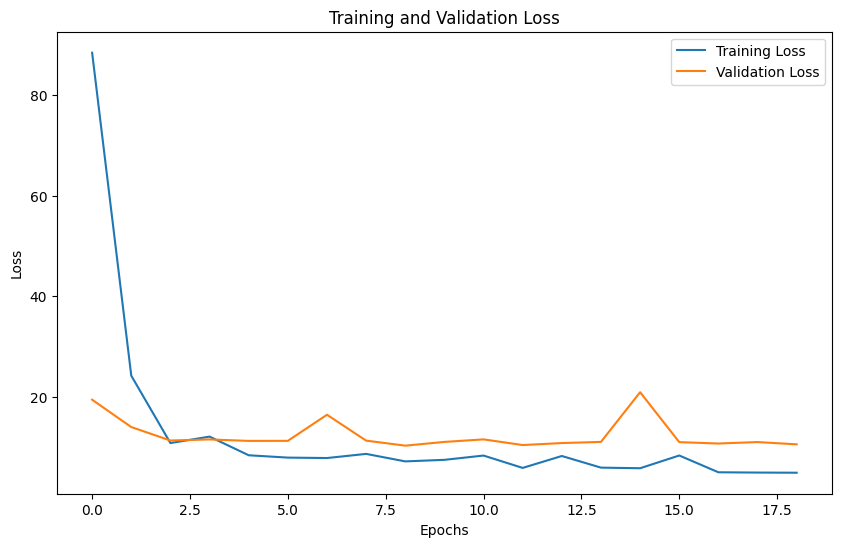

In [486]:
from scipy.stats import pearsonr
mse = mean_squared_error(y_test.flatten(), y_pred.flatten())
mae = mean_absolute_error(y_test.flatten(), y_pred.flatten())
r2 = r2_score(y_test.flatten(), y_pred.flatten())
r, _  = pearsonr(y_test.flatten(), y_pred.flatten())
mae = mae_np(y_test.flatten(), y_pred.flatten())
rmse = rmse_np(y_test.flatten(), y_pred.flatten())

print(f"Mean Squared Error: {mse:.4f}")
print(f"Mean Absolute Error: {mae:.4f}")
print(f"R^2 Score: {r2:.4f}")
print(f"r: {r:.4f}")
print(f"mae: {mae:.4f}")
print(f"rmse: {rmse:.4f}")
plt.figure(figsize=(10, 6))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
# plt.savefig(figure_dir + 'LOSS.pdf')
plt.show()

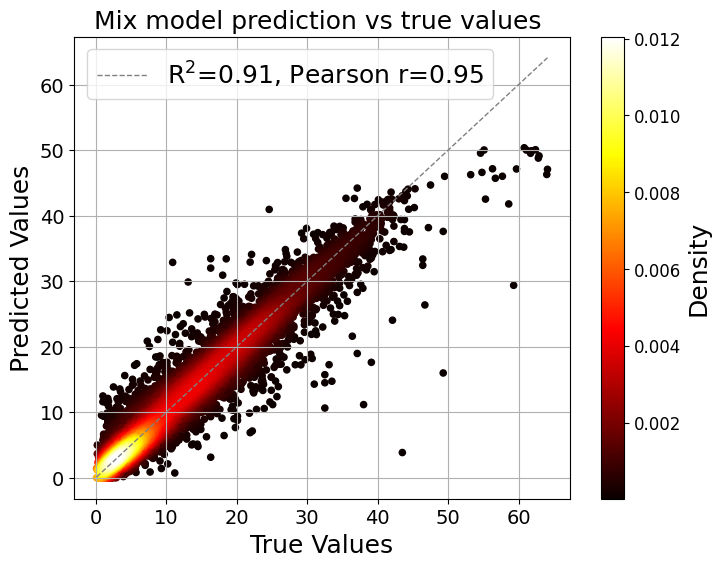

In [487]:
from matplotlib.colors import LinearSegmentedColormap
custom_cmap = LinearSegmentedColormap.from_list("custom_grey", ["#B3B3B3", "#4D4D4D"])

from scipy.stats import gaussian_kde, linregress

y_test = y_test.reshape(y_test.shape[0])
y_pred = y_pred.reshape(y_pred.shape[0])
xy = np.vstack([y_test, y_pred])
xy = np.nan_to_num(xy)
z = gaussian_kde(xy)(xy)

# Sort the points by density (optional, for better visualization)
idx = z.argsort()
y_test, y_pred, z = y_test[idx], y_pred[idx], z[idx]

fig, ax = plt.subplots(figsize=(8, 6))
sc = ax.scatter(
    y_test,
    y_pred,
    c=z,
    cmap='hot',   # or 'plasma', 'inferno', etc.
    s=20,
    edgecolor=None
)

x_line = np.linspace(y_test.min(), y_test.max(), 100)
plt.plot(x_line, x_line, linestyle='dashed', color='grey', linewidth=1,  label=f'R$^2$={r2:.2f}, Pearson r={r:.2f}')
plt.xlabel('True Values', fontsize=18)
plt.ylabel('Predicted Values',fontsize=18)
# plt.xlim([0,80])
# plt.ylim([0,80])
cbar = fig.colorbar(sc)
cbar.ax.tick_params(labelsize=12)
cbar.set_label('Density', fontsize=18)
ax.tick_params(labelsize=14)

plt.title('Mix model prediction vs true values ', fontsize=18)
plt.legend(fontsize=18)
plt.grid(True)
plt.savefig(figure_dir+'dot_dot0.pdf')

In [517]:
# import pickle
# with open("y_test_y_pred_r2_0.91.pkl", "wb") as f:
#     pickle.dump({
#         "y_test": y_test,
#         "y_pred": y_pred
#     }, f)

In [488]:
###############################################

In [514]:
# Split predictions and true values
import random
y_test_split = split_predictions_to_series(sequences_copy, seq_map_test, y_test, seq_length)
y_pred_split = split_predictions_to_series(sequences_copy, seq_map_test, y_pred, seq_length)

i_list = []
for i, l in enumerate(y_test_split):
    if len(l) >= 95 and len(l) <= 100:
        i_list.append(i)
# v = random.choice(i_list)
v = i_list[1]
# Example: Access the first time series predictions and true values
y_test_series_0 = y_test_split[v]
y_pred_series_0 = y_pred_split[v]

# Print shapes for verification
print(f"Original test series 0 shape: {y_test_series_0.shape}")
print(f"Predicted series 0 shape: {y_pred_series_0.shape}")


Original test series 0 shape: (98,)
Predicted series 0 shape: (98,)


In [515]:
len(i_list)

4

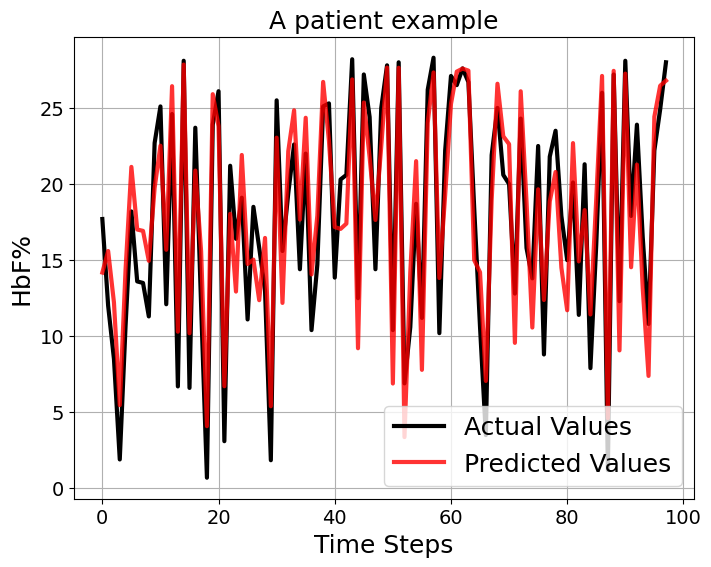

In [516]:
fig, ax = plt.subplots(figsize=(8, 6))
plt.plot(y_test_series_0.flatten(),lw=3, label='Actual Values', color='k')
plt.plot(y_pred_series_0.flatten(), lw=3, label='Predicted Values', color='red', alpha=0.8)
plt.title('A patient example', fontsize=18)
plt.xlabel('Time Steps', fontsize=18)
plt.ylabel('HbF%', fontsize=18)
ax.tick_params(labelsize=14)
plt.legend(fontsize=18)
plt.grid()
plt.savefig(figure_dir + 'example3.pdf')
plt.show()
